In [1]:
!wget https://zenodo.org/records/13741936/files/data.zip -O data.zip

--2026-11-07 04:53:08--  https://zenodo.org/records/13741936/files/data.zip
Resolving zenodo.org (zenodo.org)... 188.185.42.113, 188.185.45.63, 137.138.121.78, ...
Connecting to zenodo.org (zenodo.org)|188.185.42.113|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 320532468 (306M) [application/octet-stream]
Saving to: ‘data.zip’

data.zip            100%[===================>] 305.68M  3.57MB/s    in 1m 59s  

2026-11-07 04:55:08 (2.56 MB/s) - ‘data.zip’ saved [320532468/320532468]



In [2]:
!unzip -o -q data.zip

In [3]:
import tensorflow as tf
from tensorflow.keras import layers, models
import pandas as pd
import os


if os.path.exists('Train.csv'):
    train_df = pd.read_csv('Train.csv')
    print("Train.csv successfully loaded! Total rows:", len(train_df))
else:
    print("Train.csv not found, checking subfolders...")

    for root, dirs, files in os.walk('/content/'):
        if 'Train.csv' in files:
            print("Found Train.csv at:", os.path.join(root, 'Train.csv'))

Train.csv successfully loaded! Total rows: 39209


with fine turing

Found 39209 files belonging to 43 classes.
Using 31368 files for training.
Found 39209 files belonging to 43 classes.
Using 7841 files for validation.
--- Training Without Fine-Tuning ---
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/30
981/981 ━━━━━━━━━━━━━━━━━━━━ 152s 102ms/step - accuracy: 0.6687 - loss: 1.1019 - val_accuracy: 0.8950 - val_loss: 0.3432
Epoch 2/30
981/981 ━━━━━━━━━━━━━━━━━━━━ 45s 46ms/step - accuracy: 0.7924 - loss: 0.6252 - val_accuracy: 0.9283 - val_loss: 0.2337
Epoch 3/30
981/981 ━━━━━━━━━━━━━━━━━━━━ 42s 43ms/step - accuracy: 0.8206 - loss: 0.5338 - val_accuracy: 0.9496 - val_loss: 0.1818
Epoch 4/30
981/981 ━━━━━━━━━━━━━━━━━━━━ 42s 42ms/step - accuracy: 0.8350 - loss: 0.4868 - val_accuracy: 0.9557 - val_loss: 0.1593
Epoch 5/30
981/981 ━━━━━━━━━━━━━━━━━━━━ 42s 43ms/step - accuracy: 0.8416 - loss: 0.4629 - val_accuracy: 0.9586 - val_loss: 0.1497
Epoch 6/30
981/981 ━━━━━━━━━━━━━━━━━━━━ 42s 42ms/step - accuracy: 0.8523 - loss: 0.4293 - val_accuracy: 0.964

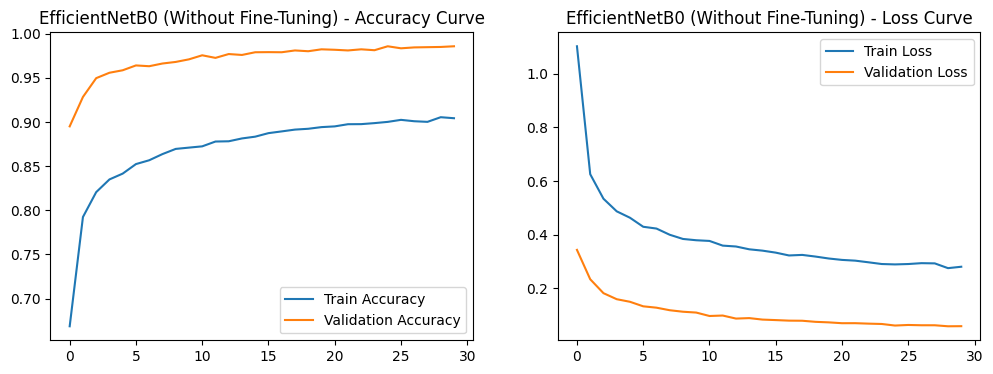


--- Classification Report (EfficientNetB0 (Without Fine-Tuning)) ---
               precision    recall  f1-score   support

           0       1.00      0.94      0.97        48
           1       0.97      0.97      0.97       468
          10       0.99      1.00      1.00       418
          11       0.98      0.99      0.99       275
          12       1.00      1.00      1.00       425
          13       1.00      1.00      1.00       449
          14       1.00      1.00      1.00       156
          15       1.00      1.00      1.00       127
          16       1.00      0.99      0.99        78
          17       1.00      1.00      1.00       225
          18       0.99      1.00      0.99       234
          19       1.00      0.98      0.99        54
           2       0.97      0.96      0.96       442
          20       1.00      1.00      1.00        84
          21       1.00      1.00      1.00        63
          22       1.00      0.98      0.99        90
          

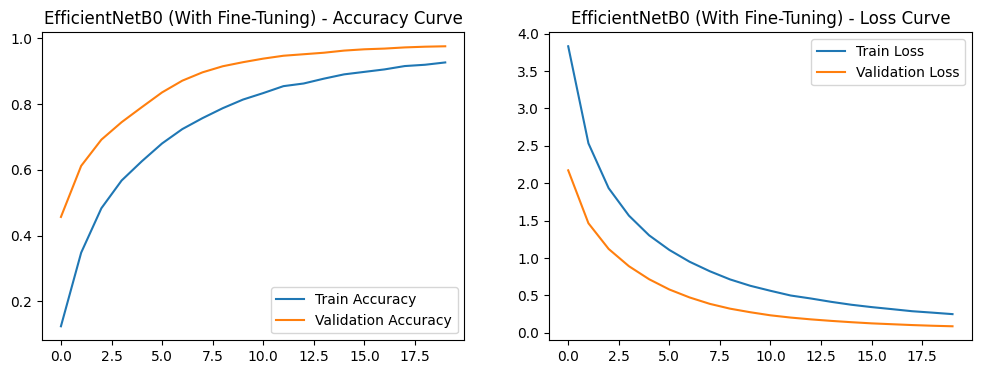


--- Classification Report (EfficientNetB0 (With Fine-Tuning)) ---
               precision    recall  f1-score   support

           0       1.00      0.92      0.96        48
           1       0.97      0.98      0.97       468
          10       0.99      1.00      1.00       418
          11       0.98      0.99      0.99       275
          12       1.00      1.00      1.00       425
          13       1.00      1.00      1.00       449
          14       1.00      0.99      1.00       156
          15       1.00      1.00      1.00       127
          16       1.00      0.99      0.99        78
          17       1.00      1.00      1.00       225
          18       1.00      0.98      0.99       234
          19       1.00      0.83      0.91        54
           2       0.96      0.92      0.94       442
          20       0.90      0.98      0.94        84
          21       1.00      1.00      1.00        63
          22       1.00      1.00      1.00        90
          23 

In [4]:
import time
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0


batch_size = 32
img_size = (224, 224)

train_ds = tf.keras.utils.image_dataset_from_directory(
    "/content/Train",
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=img_size,
    batch_size=batch_size,
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    "/content/Train",
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=img_size,
    batch_size=batch_size,
)

class_names = train_ds.class_names
num_classes = len(class_names)


AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)



def build_efficientnet_model(fine_tune=False):
  base_model = EfficientNetB0(
      input_shape=(224, 224, 3), include_top=False, weights="imagenet"
  )

  if fine_tune:

    base_model.trainable = True
    for layer in base_model.layers[:-20]:
      layer.trainable = False
  else:

    base_model.trainable = False

  model = models.Sequential([
      base_model,
      layers.GlobalAveragePooling2D(),
      layers.BatchNormalization(),
      layers.Dropout(0.5),
      layers.Dense(256, activation="relu"),
      layers.BatchNormalization(),
      layers.Dropout(0.3),
      layers.Dense(num_classes, activation="softmax"),
  ])
  return model


# --- PART A: WITHOUT FINE-TUNING ---
print("--- Training Without Fine-Tuning ---")
model_no_ft = build_efficientnet_model(fine_tune=False)
model_no_ft.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

start_time = time.time()
history_no_ft = model_no_ft.fit(
    train_ds, validation_data=val_ds, epochs=30
)
train_time_no_ft = time.time() - start_time
print(f"Training Time (Without FT): {train_time_no_ft:.2f} seconds")


# --- PART B: WITH FINE-TUNING ---
print("--- Training With Fine-Tuning ---")
model_ft = build_efficientnet_model(fine_tune=True)
model_ft.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

start_time = time.time()
history_ft = model_ft.fit(
    train_ds, validation_data=val_ds, epochs=20
)
train_time_ft = time.time() - start_time
print(f"Training Time (With FT): {train_time_ft:.2f} seconds")



def evaluate_model(model, val_dataset, history, title_prefix):

  acc = history.history["accuracy"]
  val_acc = history.history["val_accuracy"]
  loss = history.history["loss"]
  val_loss = history.history["val_loss"]

  plt.figure(figsize=(12, 4))
  plt.subplot(1, 2, 1)
  plt.plot(acc, label="Train Accuracy")
  plt.plot(val_acc, label="Validation Accuracy")
  plt.title(f"{title_prefix} - Accuracy Curve")
  plt.legend()

  plt.subplot(1, 2, 2)
  plt.plot(loss, label="Train Loss")
  plt.plot(val_loss, label="Validation Loss")
  plt.title(f"{title_prefix} - Loss Curve")
  plt.legend()
  plt.show()


  y_true = []
  y_pred = []
  for images, labels in val_dataset:
    preds = model.predict(images, verbose=0)
    y_pred.extend(np.argmax(preds, axis=1))
    y_true.extend(labels.numpy())

  print(
      f"\n--- Classification Report ({title_prefix}) ---\n",
      classification_report(y_true, y_pred, target_names=class_names),
  )
  print(f"\n--- Confusion Matrix ({title_prefix}) ---\n", confusion_matrix(y_true, y_pred))



evaluate_model(model_no_ft, val_ds, history_no_ft, "EfficientNetB0 (Without Fine-Tuning)")
evaluate_model(model_ft, val_ds, history_ft, "EfficientNetB0 (With Fine-Tuning)")